# 04 - XGBoost

XGBoost (eXtreme Gradient Boosting) builds many small decision trees one after another. Each new tree tries to fix the errors of the trees before it (**boosting**). The final prediction is the sum of all the trees.

- One `XGBRegressor` is trained **per target** (1M, 5Y, 30Y), so each can have its own settings.
- **Early stopping:** keep adding trees until the validation error (2022) hasn't improved for 100 rounds.
- **Tuning:** a small grid over `max_depth`, `learning_rate` and `min_child_weight`, choosing the combination with the lowest validation RMSE.

Experiments as before: **A** = level target, **B** = change target, **C** = change target without raw yield levels as inputs.

*Note: XGBoost and PyTorch should not be trained in the same notebook on macOS. Both ship their own OpenMP library and PyTorch can freeze. That's why every framework has its own notebook.*

In [1]:
import sys
import time
import itertools
import warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from xgboost import XGBRegressor

from src import config, features, evaluate, plots

plots.setup()
pd.set_option("display.precision", 4)
df = features.load_dataset()

## 1. Model and tuning

In [2]:
def train_xgb(X_train, y_train, X_val, y_val, params, seed=config.SEED):
    model = XGBRegressor(n_estimators=2000, early_stopping_rounds=100, subsample=0.8,
                         colsample_bytree=0.8, random_state=seed, **params)
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    return model


param_grid = {"max_depth": [2, 3, 5],
              "learning_rate": [0.01, 0.05],
              "min_child_weight": [1, 20]}
combinations = [dict(zip(param_grid, values)) for values in itertools.product(*param_grid.values())]
print(len(combinations), "combinations per target and experiment")


def rmse(a, b):
    return np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

12 combinations per target and experiment


In [3]:
best_params = {}
tuning_rows = []
for exp in config.EXPERIMENTS:
    data, mode = features.get_experiment(df, exp)
    train, val = data["train"], data["val"]
    for t in config.TARGETS:
        scores = []
        for params in combinations:
            model = train_xgb(train["X"], train["y"][t], val["X"], val["y"][t], params)
            val_rmse = rmse(val["y"][t], model.predict(val["X"]))
            scores.append((val_rmse, params, model.best_iteration))
        val_rmse, params, n_trees = min(scores, key=lambda s: s[0])
        best_params[(exp, t)] = params
        tuning_rows.append({"experiment": exp, "target": config.TARGET_NAMES[t], **params,
                            "trees (early stopping)": n_trees + 1, "val RMSE": val_rmse})
tuning = pd.DataFrame(tuning_rows)
tuning

,experiment,target,max_depth,learning_rate,min_child_weight,trees (early stopping),val RMSE
0,A,1M,3,0.05,1,115,0.7270
1,A,5Y,2,0.05,20,144,0.6538
2,A,30Y,3,0.05,20,115,0.2266
3,B,1M,5,0.01,20,6,0.1494
4,B,5Y,5,0.05,1,11,0.1901
5,B,30Y,5,0.05,1,1,0.1477
6,C,1M,2,0.01,20,1,0.1494
7,C,5Y,3,0.05,20,242,0.1863
8,C,30Y,5,0.05,1,174,0.1443


**Observations**
- In experiment A (level) the best settings still give a validation RMSE of 0.23 to 0.73 percentage points, which is huge. In 2022 the yields already went above the training range.
- In the change experiments, early stopping often stops after very few trees (1 to 11). With so few trees and a small learning rate, the model barely moves away from a constant prediction close to zero change, which is almost the naive forecast. This is a sign that there is very little learnable signal in the data.
- Only the 5Y and 30Y models in experiment C kept more trees (242 and 174), so they learned more structure.

## 2. Test results for the three experiments

In [4]:
results, models = {}, {}
for exp in config.EXPERIMENTS:
    data, mode = features.get_experiment(df, exp)
    train, val, test = data["train"], data["val"], data["test"]
    start = time.time()
    preds = []
    for t in config.TARGETS:
        model = train_xgb(train["X"], train["y"][t], val["X"], val["y"][t], best_params[(exp, t)])
        models[(exp, t)] = model
        preds.append(model.predict(test["X"]))
    train_time = time.time() - start
    pred_level = evaluate.to_level(np.column_stack(preds), test["today"], mode)
    evaluate.save_predictions("XGBoost", exp, config.SEED, test, pred_level)
    results[exp] = evaluate.evaluate(test["future"], pred_level, test["today"])
    print(f"\n=== XGBoost, experiment {config.EXPERIMENT_NAMES[exp]} (3 models trained in {train_time:.1f}s) ===")
    print(results[exp].round(4))
    if exp == "C":
        time_c = train_time

evaluate.save_run_info("XGBoost", {"train_seconds": time_c,
                                   "lines_of_code": evaluate.count_lines(train_xgb),
                                   "hyperparameters": 7,
                                   "tuning_combinations": len(combinations)})


=== XGBoost, experiment A: level, all features (3 models trained in 0.7s) ===
          RMSE     MAE       R2  R2_change  skill_vs_naive  direction_acc
target                                                                   
1M      2.3621  2.2559 -10.3870  -257.8051        -15.0868         0.5196
5Y      1.2162  1.1682 -11.4263   -76.9645         -7.8195         0.4567
30Y     0.5379  0.4826  -0.5891   -22.6309         -3.8430         0.4467



=== XGBoost, experiment B: change, all features (3 models trained in 0.5s) ===
          RMSE     MAE      R2  R2_change  skill_vs_naive  direction_acc
target                                                                  
1M      0.1469  0.0619  0.9560    -0.0003         -0.0001         0.4918
5Y      0.1466  0.1146  0.8196    -0.1321         -0.0628         0.4567
30Y     0.1117  0.0874  0.9315    -0.0186         -0.0055         0.4489



=== XGBoost, experiment C: change, no yield levels (3 models trained in 0.8s) ===
          RMSE     MAE      R2  R2_change  skill_vs_naive  direction_acc
target                                                                  
1M      0.1468  0.0616  0.9560     0.0002          0.0001         0.4930
5Y      0.1400  0.1075  0.8354    -0.0328         -0.0151         0.5133
30Y     0.1268  0.0972  0.9117    -0.3125         -0.1414         0.5387


## 3. Why predicting the level fails for trees

The plot compares experiment A (level target) with experiment C (change target) on the test period. The dashed line is the highest value of each yield in the training data (2010-2021).

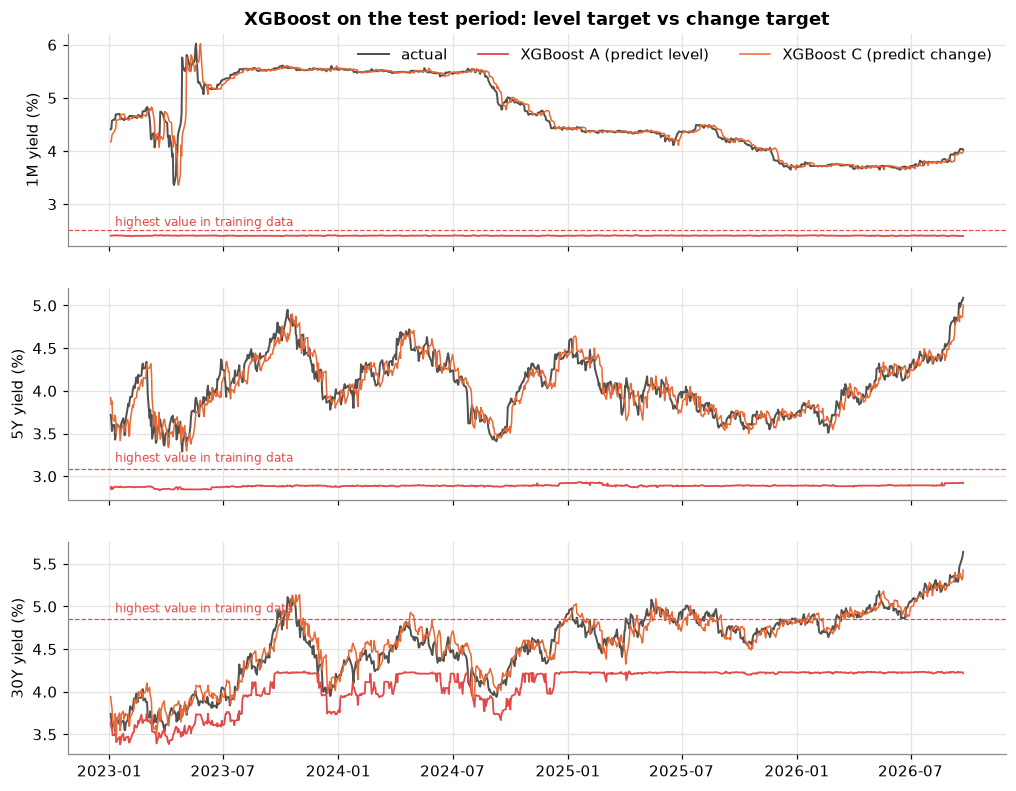

In [5]:
pred_a = pd.read_csv(config.PRED_DIR / "XGBoost_A_seed42.csv", index_col=0, parse_dates=True)
pred_c = pd.read_csv(config.PRED_DIR / "XGBoost_C_seed42.csv", index_col=0, parse_dates=True)
train_max = df.loc[:config.TRAIN_END, config.TARGETS].max()

fig, axes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True)
for ax, t in zip(axes, config.TARGETS):
    ax.plot(pred_a.index, pred_a[f"{t}_actual"], color="#52514e", linewidth=1.3, label="actual")
    ax.plot(pred_a.index, pred_a[f"{t}_pred"], color=plots.RED, linewidth=1.2, label="XGBoost A (predict level)")
    ax.plot(pred_c.index, pred_c[f"{t}_pred"], color=plots.ORANGE, linewidth=1, label="XGBoost C (predict change)")
    ax.axhline(train_max[t], color=plots.RED, linestyle="--", linewidth=0.8)
    ax.text(pred_a.index[5], train_max[t] + 0.08, "highest value in training data", fontsize=8, color=plots.RED)
    ax.set_ylabel(f"{config.TARGET_NAMES[t]} yield (%)")
axes[0].legend(loc="upper right", ncol=3)
axes[0].set_title("XGBoost on the test period: level target vs change target")
plots.save(fig, "04_xgb_level_vs_change")
plt.show()

**Observations**
- Exactly what the EDA predicted: in experiment A the predictions **can't go above the training range** (dashed line). For the 1M they sit around 2.4% while the real yield is between 3.4% and 6%. For the 5Y they stay around 2.9%, and for the 30Y they are capped at about 4.2%.
- This gives errors of 1 to 2.4 percentage points (skill vs naive between −3.8 and −15, negative R²). Following the original case study's setup with tree models would give useless forecasts in 2023-2026.
- Experiment C's predictions follow the actual yield, because they're today's yield plus a small predicted change.
- **Lesson:** decision trees can't extrapolate. Predicting the change keeps the target inside the range seen in training.
- Even so, C doesn't beat naive: skill is +0.0001 (1M), −0.015 (5Y) and −0.14 (30Y). The 30Y model chosen on validation overfitted.

## 4. Feature importance (experiment C)

XGBoost has a built-in importance measure. **Gain** is how much each feature reduced the error, summed over all the splits that used it. It's normalised to 1 for each target and then averaged.

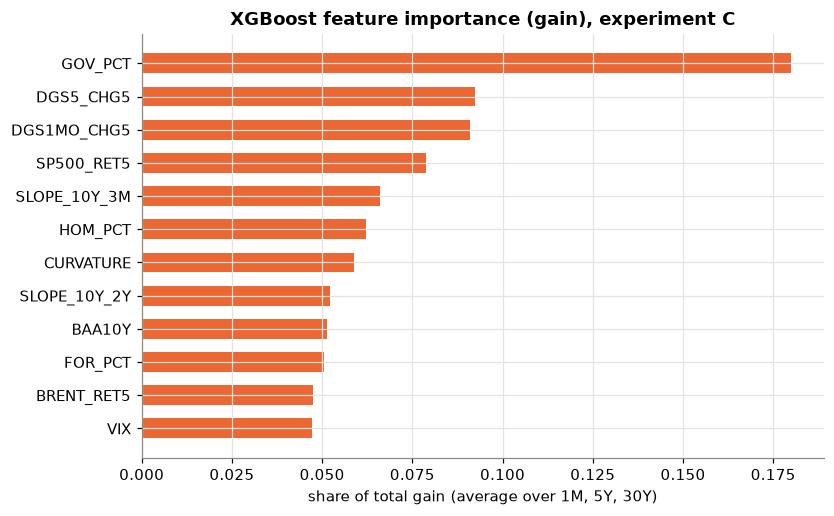

,1M,5Y,30Y,mean
GOV_PCT,0.382,0.084,0.074,0.180
DGS5_CHG5,0.165,0.050,0.063,0.092
DGS1MO_CHG5,0.150,0.063,0.060,0.091
SP500_RET5,0.113,0.066,0.057,0.079
SLOPE_10Y_3M,0.053,0.072,0.073,0.066
HOM_PCT,0.019,0.075,0.092,0.062
CURVATURE,0.025,0.076,0.076,0.059
SLOPE_10Y_2Y,0.026,0.070,0.061,0.052
BAA10Y,0.021,0.074,0.059,0.051
FOR_PCT,0.000,0.078,0.074,0.051


In [6]:
gain = pd.DataFrame({config.TARGET_NAMES[t]: pd.Series(models[("C", t)].get_booster().get_score(importance_type="gain"))
                     for t in config.TARGETS}).reindex(features.NO_LEVEL_FEATURES).fillna(0)
gain = gain / gain.sum()
gain["mean"] = gain.mean(axis=1)
gain = gain.sort_values("mean", ascending=False)
evaluate.save_importance("XGBoost", gain["mean"], "gain")

fig, ax = plt.subplots(figsize=(8, 5))
top = gain.head(12).iloc[::-1]
ax.barh(top.index, top["mean"], color=plots.MODEL_COLORS["XGBoost"], height=0.6)
ax.set_xlabel("share of total gain (average over 1M, 5Y, 30Y)")
ax.set_title("XGBoost feature importance (gain), experiment C")
plots.save(fig, "04_xgb_importance")
plt.show()
gain.round(3).head(10)

## 5. SHAP values: explaining individual predictions

Gain only says *how much* a feature is used, not *in which direction* it pushes the prediction. **SHAP** (SHapley Additive exPlanations) splits every single prediction into a contribution from each feature, based on Shapley values from game theory. For tree models the values are exact and quick to compute (TreeExplainer).

The plot below is for the **5Y yield change model** on the test set. Each dot is one day: red means a high feature value, blue a low one, and the position shows how much it pushed that day's prediction up or down.

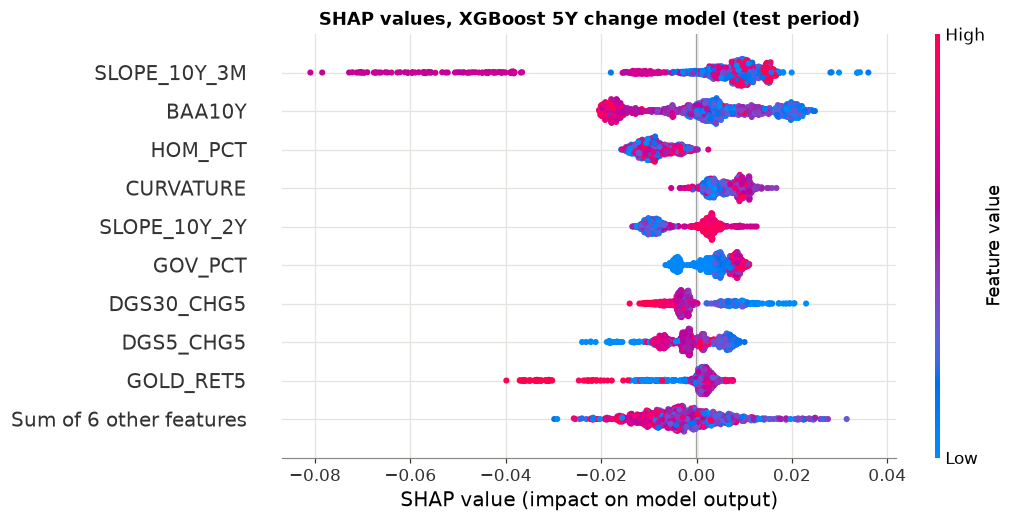

In [7]:
model_5y = models[("C", "DGS5")]
data_c, _ = features.get_experiment(df, "C")
explainer = shap.TreeExplainer(model_5y)
shap_values = explainer(data_c["test"]["X"])
shap.plots.beeswarm(shap_values, max_display=10, show=False)
fig = plt.gcf()
fig.set_size_inches(9, 5)
plt.title("SHAP values, XGBoost 5Y change model (test period)")
plots.save(fig, "04_xgb_shap_5y")
plt.show()

One single prediction explained, the day with the largest predicted move:

In [8]:
day = int(np.abs(shap_values.values.sum(axis=1)).argmax())
print("Date:", data_c["test"]["X"].index[day].date())
print(f"Base value (average prediction): {shap_values.base_values[day]*100:.2f} bp")
print(f"Predicted 5-day change:          {(shap_values.base_values[day] + shap_values.values[day].sum())*100:.2f} bp")
print(f"Actual 5-day change:             {data_c['test']['y']['DGS5'].iloc[day]*100:.2f} bp")
contrib = pd.Series(shap_values.values[day] * 100, index=features.NO_LEVEL_FEATURES)
contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(6).round(2).rename("contribution (bp)")

Date: 2024-11-15
Base value (average prediction): -0.21 bp
Predicted 5-day change:          -12.32 bp
Actual 5-day change:             0.00 bp


SLOPE_10Y_3M   -5.62
HOM_PCT        -1.25
SLOPE_10Y_2Y   -1.15
GOLD_RET5      -1.03
DGS5_CHG5      -0.97
VIX            -0.61
Name: contribution (bp), dtype: float32

**Observations**
- **Gain importance:** `GOV_PCT` (the Fed's share of the debt) is top on average, but almost all of that comes from the 1M model, which has a single tree. The debt shares change slowly, so the trees mostly use them as a "which period are we in" indicator (QE or QT), not as a cause of next week's move. The momentum features (`DGS5_CHG5`, `DGS1MO_CHG5`) and the S&P 500 return come next.
- **SHAP (5Y model):**
  - The 10Y-3M slope and the Baa credit spread have the largest effects.
  - A **wide credit spread (red) pushes the prediction down**: in stressful times investors buy government bonds and expect rate cuts, so yields fall. That matches economic intuition.
  - A big rise of the 30Y in the past week (`DGS30_CHG5` red) pushes the prediction slightly down, i.e. a partial reversal.
- Most SHAP values are within ±2 bp, while a typical weekly move is about 11 bp. The model's view is weak compared with the noise.
- **Single prediction (15 Nov 2024):** the model predicted −12.3 bp for the 5Y, mostly because of the inverted 10Y-3M slope (−5.6 bp). The actual move was 0 bp. Even the model's strongest signal was wrong here.
- **Transparency:** with gain and SHAP, every XGBoost prediction can be broken down feature by feature. This is a big advantage over the neural networks.